# Create Distances Constraints

The goal of this notebook is to determine a set of distance constraints between the TCRs and pMHCs that can be used in structure prediction methods for TCR:pMHC interactions. The restraints will be based off distances between the Cα atoms of the CDR anchoring residues and TCR-contact positions on the MHC molecules.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from python_pdb.parsers import parse_pdb_to_pandas

In [2]:
IMGT_CDR1 = set(range(27, 38 + 1))
IMGT_CDR2 = set(range(56, 65 + 1))
IMGT_CDR3 = set(range(105, 117 + 1))

In [3]:
MHC_TCR_CONTACT_POSITIONS = {
    'alpha': ['62', '63', '65', '66', '68', '69', '70', '72', '73', '75', '76', '79'],
    'beta': ['58', '61A', '62', '63', '65', '66', '67', '69', '70', '72', '72A', '73', '76', '77'],
}

processed_mhc_tcr_contact_positions = [
    (
        helix,
        int(''.join([char for char in resid if char.isnumeric()])),
        ''.join([char for char in resid if not char.isnumeric()]),
    )
    for helix, residues in MHC_TCR_CONTACT_POSITIONS.items()
    for resid in residues
]

In [4]:
MHC_I_BETA_HELIX_START = 1000

## Load data and compute interfaces

In [5]:
summary_csv = pd.read_csv('../data/raw/structures_summary.csv')

In [6]:
def find_anchors(
    cdr_df: pd.DataFrame, structure_df: pd.DataFrame, num_anchors: int = 1
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Get the anchors of a cdr loop. DOES NOT SUPPORT MULTIPLE MODELS."""
    cdr_start_info = tuple(cdr_df.iloc[0][['chain_id', 'residue_seq_id', 'residue_insert_code']].tolist())
    cdr_end_info = tuple(cdr_df.iloc[-1][['chain_id', 'residue_seq_id', 'residue_insert_code']].tolist())

    residues = list(structure_df.groupby(['chain_id', 'residue_seq_id', 'residue_insert_code'], dropna=False))

    for i, (residue_info, _) in enumerate(residues):
        res_info_adj = (residue_info[0], residue_info[1], None) if pd.isna(residue_info[-1]) else residue_info

        if cdr_start_info == res_info_adj:
            start_anchor = pd.concat([res for _, res in residues[i - num_anchors : i]])

        if cdr_end_info == res_info_adj:
            end_anchor = pd.concat([res for _, res in residues[(i + 1) : (i + 1) + num_anchors]])
            break

    return start_anchor, end_anchor


def _cdr_anchor_name(chain_type: str, cdr: int) -> str:
    return f"CDR{cdr}{'alpha' if chain_type == 'Achain' else 'beta'}"


def assign_tcr_contact_positions(mhc_domain: pd.DataFrame, mhc_type: str) -> pd.Series:
    mhc_domain = mhc_domain.copy()

    mhc_domain['mhc_helix'] = None

    if mhc_type == 'MH1':
        mhc_domain.loc[
            (mhc_domain['chain_type'] == 'mhc_chain1') & (mhc_domain['residue_seq_id'] < MHC_I_BETA_HELIX_START),
            'mhc_helix',
        ] = 'alpha'

        mhc_domain.loc[
            (mhc_domain['chain_type'] == 'mhc_chain1') & (mhc_domain['residue_seq_id'] >= MHC_I_BETA_HELIX_START),
            'mhc_helix',
        ] = 'beta'

        mhc_domain.loc[
            (mhc_domain['chain_type'] == 'mhc_chain1') & (mhc_domain['residue_seq_id'] >= MHC_I_BETA_HELIX_START),
            'residue_seq_id',
        ] = (
            mhc_domain.loc[
                (mhc_domain['chain_type'] == 'mhc_chain1') & (mhc_domain['residue_seq_id'] >= MHC_I_BETA_HELIX_START),
                'residue_seq_id',
            ]
            - MHC_I_BETA_HELIX_START
        )

    else:
        mhc_domain.loc[(mhc_domain['chain_type'] == 'mhc_chain1'), 'mhc_helix'] = 'alpha'
        mhc_domain.loc[(mhc_domain['chain_type'] == 'mhc_chain2'), 'mhc_helix'] = 'beta'

    mhc_domain_id = mhc_domain[['mhc_helix', 'residue_seq_id', 'residue_insert_code']].fillna('').apply(tuple, axis=1)

    return mhc_domain_id.map(
        lambda domain_id: (
            f'{domain_id[0]}_{domain_id[1]}{domain_id[2]}' if domain_id in processed_mhc_tcr_contact_positions else None
        ),
    )

In [7]:
interfaces = []

for _, row in summary_csv.iterrows():
    with open(os.path.join('../data/raw/structures', row['path']), 'r') as fh:
        structure_df = parse_pdb_to_pandas(fh.read())

    chain_map = {
        chain_id: chain_type
        for chain_type, chain_id in row.filter(regex='chain').to_dict().items()
        if not pd.isna(chain_id)
    }

    structure_df['chain_type'] = structure_df['chain_id'].map(chain_map)
    structure_df['cdr'] = None

    tcr_selection = (structure_df['chain_type'] == 'Achain') | (structure_df['chain_type'] == 'Bchain')

    structure_df.loc[tcr_selection & structure_df['residue_seq_id'].isin(IMGT_CDR1), 'cdr'] = 1
    structure_df.loc[tcr_selection & structure_df['residue_seq_id'].isin(IMGT_CDR2), 'cdr'] = 2
    structure_df.loc[tcr_selection & structure_df['residue_seq_id'].isin(IMGT_CDR3), 'cdr'] = 3

    structure_df['cdr_anchor'] = None

    for cdr_info, cdr_df in structure_df.groupby(['chain_type', 'cdr']):
        start_anchor, end_anchor = find_anchors(cdr_df, structure_df)

        structure_df.loc[start_anchor.index, 'cdr_anchor'] = _cdr_anchor_name(*cdr_info) + '_start'
        structure_df.loc[end_anchor.index, 'cdr_anchor'] = _cdr_anchor_name(*cdr_info) + '_end'

    structure_df['mhc_tcr_contact'] = None
    mhc_selection = (structure_df['chain_type'] == 'mhc_chain1') | (structure_df['chain_type'] == 'mhc_chain2')

    structure_df.loc[mhc_selection, 'mhc_tcr_contact'] = assign_tcr_contact_positions(
        structure_df[mhc_selection], row['mhc_type']
    )

    cdr_anchors = structure_df[(structure_df['cdr_anchor'].notna()) & (structure_df['atom_name'] == 'CA')]
    mhc_tcr_contact_positions = structure_df[
        structure_df['mhc_tcr_contact'].notna() & (structure_df['atom_name'] == 'CA')
    ]

    interface = cdr_anchors.merge(mhc_tcr_contact_positions, how='cross', suffixes=('_tcr', '_mhc'))
    interface['distance'] = np.sqrt(
        np.square(interface['pos_x_tcr'] - interface['pos_x_mhc'])
        + np.square(interface['pos_y_tcr'] - interface['pos_y_mhc'])
        + np.square(interface['pos_z_tcr'] - interface['pos_z_mhc'])
    )

    interfaces.append(interface)

interfaces = pd.concat(interfaces)

### Remove constraints that are not present in all structures

In [8]:
group_sizes = interfaces.groupby(['cdr_anchor_tcr', 'mhc_tcr_contact_mhc']).size()
max_group_size = group_sizes.max()
groups_to_keep = group_sizes[group_sizes == max_group_size].index


selected_interfaces = interfaces[
    interfaces.set_index(['cdr_anchor_tcr', 'mhc_tcr_contact_mhc']).index.isin(groups_to_keep)
]

## Analyse strategy for selecting constraints

In [ ]:
def coeffecient_of_variation(distances: np.ndarray | pd.Series) -> np.ndarray:
    """CV = mu / sigma."""
    return np.std(distances) / np.mean(distances)


def inv_coeffecient_of_variation(distances: np.ndarray | pd.Series) -> np.ndarray:
    """CV = mu * sigma."""
    return np.std(distances) * np.mean(distances)

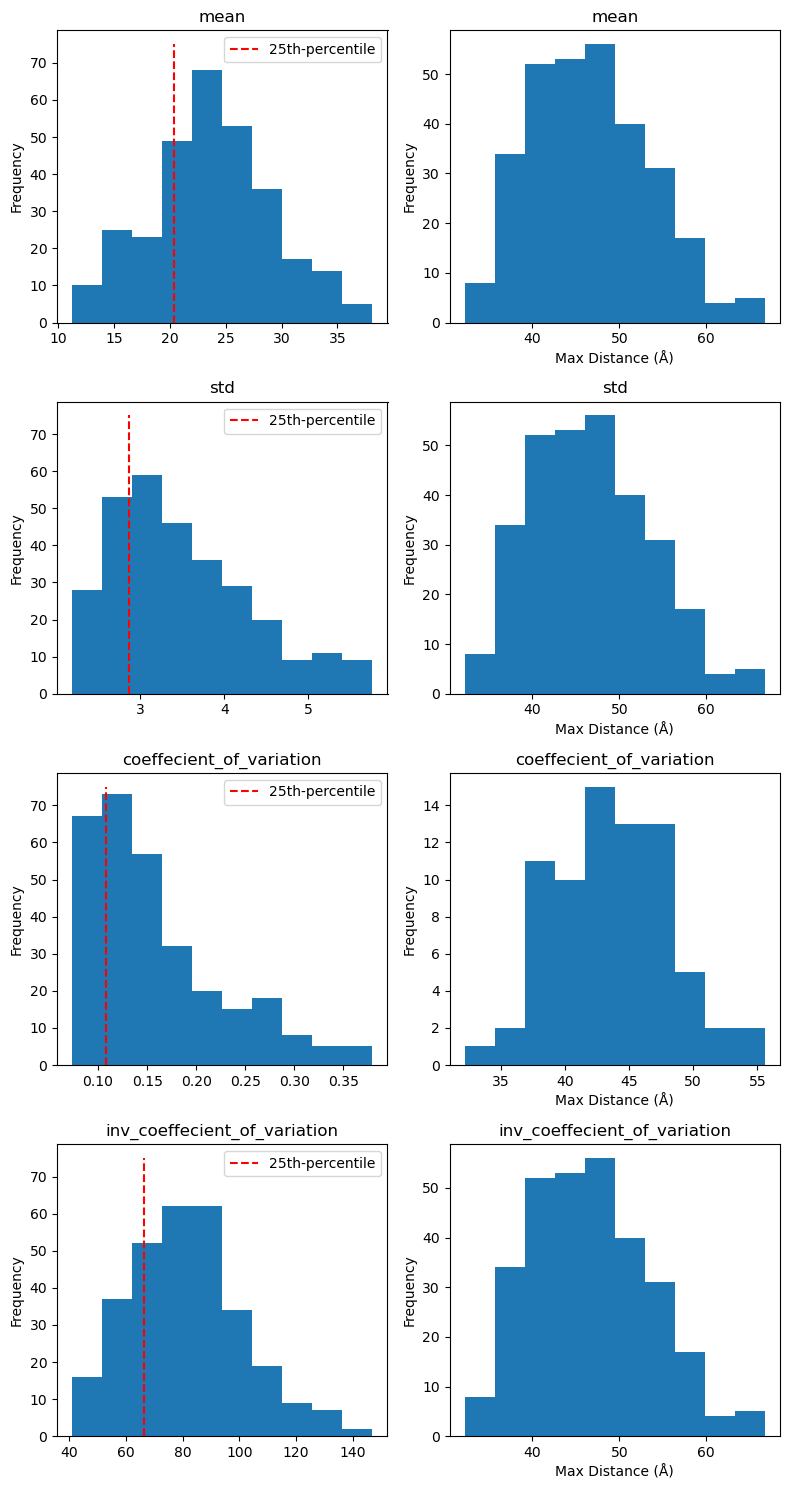

In [10]:
distances = selected_interfaces.groupby(['cdr_anchor_tcr', 'mhc_tcr_contact_mhc'])['distance']

constraint_strategies = {}

fig, axes = plt.subplots(4, 2, figsize=(8, 15))

for i, func in enumerate((np.mean, np.std, coeffecient_of_variation, inv_coeffecient_of_variation)):
    distances_agg = distances.apply(func)
    threshold = distances_agg.quantile(0.25)

    distances_agg.plot.hist(ax=axes[i, 0], label='')
    axes[i, 0].vlines(threshold, 0, 75, linestyles='dashed', colors='red', label='25th-percentile')
    axes[i, 0].set_title(func.__name__)
    axes[i, 0].legend()

    selected_distances = selected_interfaces.groupby(['cdr_anchor_tcr', 'mhc_tcr_contact_mhc']).filter(
        lambda group, threshold=threshold: (group['distance'].std() / group['distance'].mean()) <= threshold
    )

    constraints = selected_distances.groupby(['cdr_anchor_tcr', 'mhc_tcr_contact_mhc'])['distance'].max().reset_index()

    constraints['distance'].plot.hist(ax=axes[i, 1])
    axes[i, 1].set_title(func.__name__)
    axes[i, 1].set_xlabel('Max Distance (Å)')

    constraint_strategies[func.__name__] = constraints

plt.tight_layout()
plt.show()

The chosen strategy is to use the 25-th percentile of the coeffecient of variation of distances to select optimal constraints. This balances having high consitency and low mean distances.

In [11]:
constraint_strategies['coeffecient_of_variation'].to_csv(
    '../data/processed/tcr_pmhc_distance_restaints.csv', index=False
)